In [1]:

# ==========================================
# MILESTONE 1 - MEDICAL COST EDA
# TAHAP 1: LOAD DATASET
# ==========================================

import pandas as pd

from google.colab import files

uploaded = files.upload()

df = pd.read_csv('insurance.csv')

print("Dataset berhasil dimuat!")
print("Ukuran dataset:", df.shape)

df.head()

Saving insurance.csv to insurance.csv
Dataset berhasil dimuat!
Ukuran dataset: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
# ==========================================
# TAHAP 2: MISSING VALUE & DUPLICATE CHECK
# ==========================================

# Memeriksa jumlah data kosong pada setiap kolom
print("Jumlah Missing Value:")
print(df.isnull().sum())

# Menghitung total seluruh data kosong
print("\nTotal Missing Value:")
print(df.isnull().sum().sum())

# Memeriksa jumlah baris duplikat
print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

Jumlah Missing Value:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Total Missing Value:
0

Jumlah Data Duplikat:
1


In [3]:
# Menampilkan baris data yang terduplikasi
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [4]:
# ==========================================
# MEMBERSIHKAN DATA DUPLIKAT
# ==========================================

# Menghapus baris duplikat
df = df.drop_duplicates()

# Memeriksa kembali ukuran dataset
print("Ukuran dataset setelah dibersihkan:", df.shape)

# Memeriksa kembali jumlah data duplikat
print("Jumlah duplikat setelah dibersihkan:", df.duplicated().sum())

Ukuran dataset setelah dibersihkan: (1337, 7)
Jumlah duplikat setelah dibersihkan: 0


In [5]:
# ==========================================
# TAHAP 3: CENTRAL TENDENCY
# ==========================================

# Memilih kolom yang memiliki tipe data numerik
numeric = df.select_dtypes(include='number').columns.tolist()

# Menghitung Mean, Median, dan Modus
for col in numeric:
    print(f"\nKolom: {col}")
    print("Mean   :", df[col].mean())
    print("Median :", df[col].median())
    print("Modus  :", df[col].mode()[0])


Kolom: age
Mean   : 39.222139117427076
Median : 39.0
Modus  : 18

Kolom: bmi
Mean   : 30.66345175766642
Median : 30.4
Modus  : 32.3

Kolom: children
Mean   : 1.0957367240089753
Median : 1.0
Modus  : 0

Kolom: charges
Mean   : 13279.121486655948
Median : 9386.1613
Modus  : 1121.8739


In [6]:
# ==========================================
# TAHAP 4: DISPERSION
# ==========================================

for col in numeric:
    std = df[col].std()
    variance = df[col].var()
    iqr = df[col].quantile(0.75) - df[col].quantile(0.25)
    cv = (std / df[col].mean()) * 100

    print(f"\nKolom: {col}")
    print("Std Dev :", std)
    print("Variance:", variance)
    print("IQR     :", iqr)
    print("CV (%)  :", cv)


Kolom: age
Std Dev : 14.044332734156422
Variance: 197.2432819476976
IQR     : 24.0
CV (%)  : 35.80715649421651

Kolom: bmi
Std Dev : 6.100468409615801
Variance: 37.21571481672034
IQR     : 8.410000000000004
CV (%)  : 19.8949174340445

Kolom: children
Std Dev : 1.2055714286412185
Variance: 1.4534024695560286
IQR     : 2.0
CV (%)  : 110.0238225319665

Kolom: charges
Std Dev : 12110.359656344179
Variance: 146660811.00600868
IQR     : 11911.37345
CV (%)  : 91.19850035647129


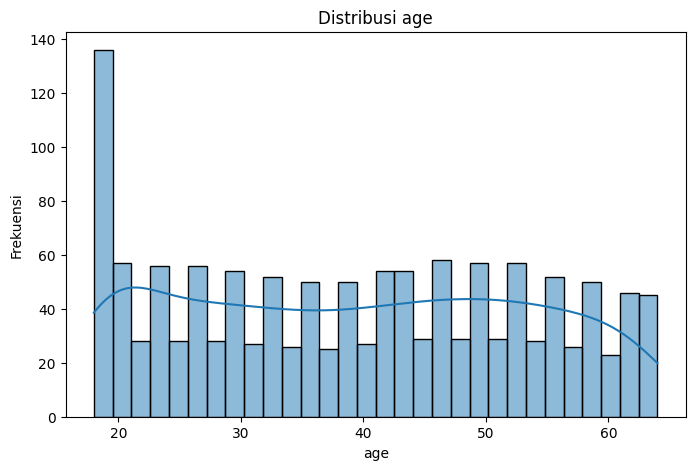

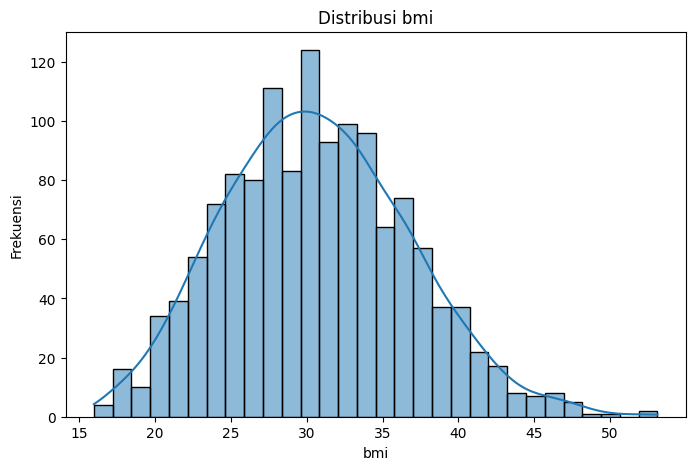

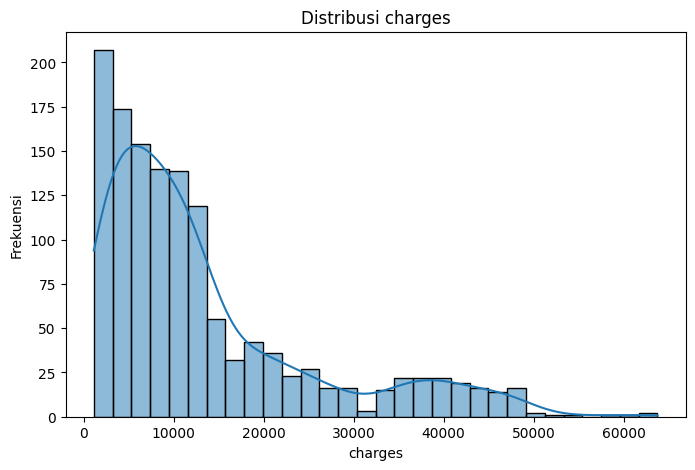

In [7]:
# ==========================================
# TAHAP 5: UNIVARIATE VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Daftar kolom yang akan divisualisasikan
kolom_visualisasi = ['age', 'bmi', 'charges']

# Membuat histogram untuk setiap kolom
for col in kolom_visualisasi:
    plt.figure(figsize=(8, 5))

    sns.histplot(data=df, x=col, bins=30, kde=True)

    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')

    plt.show()

### Kesimpulan Univariate Visualization

Berdasarkan hasil visualisasi univariat menggunakan histogram, variabel age menunjukkan bahwa usia peserta cukup beragam dan tersebar pada beberapa rentang usia. Pada variabel bmi, frekuensi tertinggi terlihat berada di sekitar nilai 30. Sementara itu, variabel charges menunjukkan distribusi yang menceng ke kanan (*right-skewed*), karena sebagian besar data terkumpul pada nilai biaya yang lebih rendah dan hanya sebagian kecil memiliki biaya yang sangat tinggi. Hasil visualisasi ini menunjukkan bahwa distribusi setiap variabel memiliki karakteristik yang berbeda.

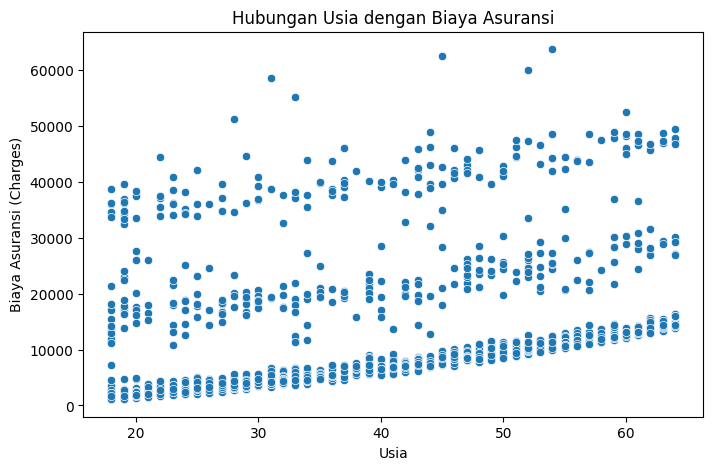

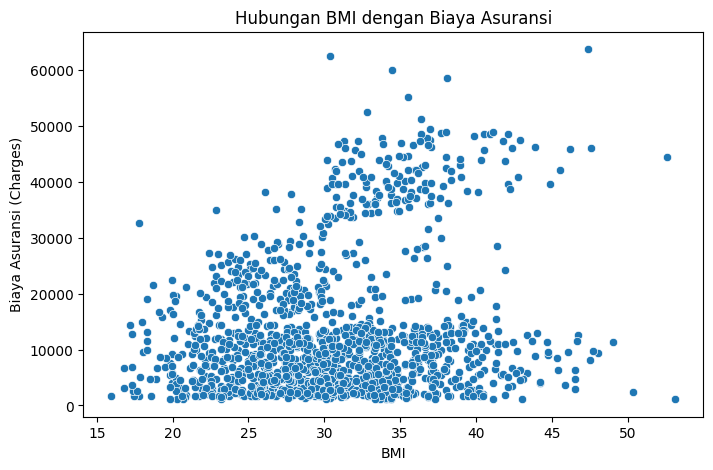

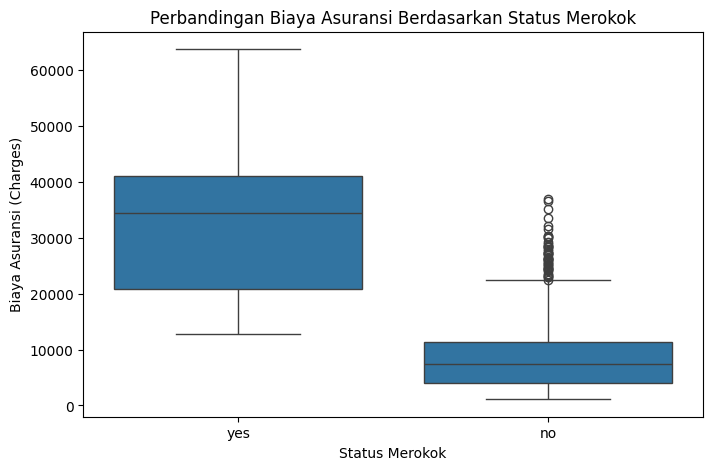

In [8]:
# ==========================================
# TAHAP 6: BIVARIATE VISUALIZATION
# ==========================================

# Grafik 1: Hubungan Age dengan Charges
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='charges')
plt.title('Hubungan Usia dengan Biaya Asuransi')
plt.xlabel('Usia')
plt.ylabel('Biaya Asuransi (Charges)')
plt.show()


# Grafik 2: Hubungan BMI dengan Charges
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='bmi', y='charges')
plt.title('Hubungan BMI dengan Biaya Asuransi')
plt.xlabel('BMI')
plt.ylabel('Biaya Asuransi (Charges)')
plt.show()


# Grafik 3: Perbandingan Smoker dengan Charges
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='smoker', y='charges')
plt.title('Perbandingan Biaya Asuransi Berdasarkan Status Merokok')
plt.xlabel('Status Merokok')
plt.ylabel('Biaya Asuransi (Charges)')
plt.show()

### Interpretasi Bivariate Visualization

Berdasarkan hasil visualisasi bivariat, grafik hubungan antara variabel `age` dan `charges` menunjukkan pola positif, yaitu biaya asuransi cenderung meningkat seiring bertambahnya usia. Hal ini didukung oleh nilai korelasi sebesar 0,298 yang menunjukkan hubungan positif lemah. Pada hubungan `bmi` dan `charges`, terlihat kecenderungan kenaikan, tetapi polanya tidak terlalu kuat atau jelas, dengan nilai korelasi sebesar 0,198. Sementara itu, boxplot menunjukkan bahwa kelompok perokok (`smoker = yes`) memiliki sebaran biaya asuransi yang lebih tinggi dibandingkan kelompok bukan perokok (`smoker = no`). Hal ini diperkuat oleh rata-rata biaya asuransi kelompok perokok sebesar 32.050,23, sedangkan kelompok bukan perokok sebesar 8.440,66. Dari ketiga visualisasi tersebut, status merokok menunjukkan perbedaan biaya yang paling mencolok, sedangkan usia dan BMI memiliki hubungan positif dengan biaya asuransi, tetapi tergolong lemah.

In [9]:
# Korelasi usia, BMI, dan biaya asuransi
print("Korelasi antarvariabel:")
print(df[['age', 'bmi', 'charges']].corr())

# Rata-rata dan median biaya berdasarkan status merokok
print("\nBiaya asuransi berdasarkan status merokok:")
print(df.groupby('smoker')['charges'].agg(['count', 'mean', 'median']))

Korelasi antarvariabel:
              age       bmi   charges
age      1.000000  0.109344  0.298308
bmi      0.109344  1.000000  0.198401
charges  0.298308  0.198401  1.000000

Biaya asuransi berdasarkan status merokok:
        count          mean       median
smoker                                  
no       1063   8440.660307   7345.72660
yes       274  32050.231832  34456.34845


## Tahap 7: Insight dan Hipotesis
### A. Insight
1. **Kualitas Dataset:** Dataset Medical Cost Personal memiliki 1.338 baris dan 7 kolom. Setelah pemeriksaan, ditemukan 1 data duplikat yang kemudian dihapus sehingga tersisa 1.337 baris. Dataset tidak memiliki missing value.

2. **Distribusi Biaya Asuransi:** Variabel `charges` memiliki distribusi menceng ke kanan (*right-skewed*). Hal ini menunjukkan bahwa sebagian besar peserta memiliki biaya asuransi yang relatif lebih rendah, sedangkan sebagian kecil peserta memiliki biaya yang sangat tinggi.

3. **Hubungan Usia dan BMI dengan Biaya Asuransi:** Usia memiliki korelasi positif lemah dengan biaya asuransi sebesar 0,298. Sementara itu, BMI memiliki korelasi positif sangat lemah sebesar 0,198. Artinya, kedua variabel tersebut memiliki kecenderungan hubungan positif dengan biaya asuransi, tetapi hubungannya tidak kuat.

4. **Perbedaan Biaya Berdasarkan Status Merokok:** Kelompok perokok memiliki rata-rata biaya asuransi sebesar 32.050,23, sedangkan kelompok bukan perokok sebesar 8.440,66. Hal ini menunjukkan adanya perbedaan biaya yang cukup besar antara kedua kelompok.

### B. Hipotesis untuk Milestone 2

1. **Hipotesis 1:** Terdapat perbedaan biaya asuransi (`charges`) yang signifikan antara peserta yang merokok (`smoker = yes`) dan peserta yang tidak merokok (`smoker = no`).

2. **Hipotesis 2:** Terdapat hubungan antara usia (`age`) dan biaya asuransi (`charges`).

3. **Hipotesis 3:** Terdapat hubungan antara BMI (`bmi`) dan biaya asuransi (`charges`).

In [10]:
# ==========================================
# TAHAP 8: INTERACTIVE PLOTLY DASHBOARD
# ==========================================

import plotly.express as px

# Grafik 1: Hubungan Usia dengan Biaya Asuransi
fig1 = px.scatter(
    df,
    x='age',
    y='charges',
    color='smoker',
    title='Hubungan Usia dengan Biaya Asuransi',
    labels={
        'age': 'Usia',
        'charges': 'Biaya Asuransi',
        'smoker': 'Status Merokok'
    }
)

fig1.show()

# Grafik 2: Perbandingan Biaya Asuransi Berdasarkan Status Merokok
fig2 = px.box(
    df,
    x='smoker',
    y='charges',
    color='smoker',
    title='Biaya Asuransi Berdasarkan Status Merokok',
    labels={
        'smoker': 'Status Merokok',
        'charges': 'Biaya Asuransi'
    }
)

fig2.show()